<style> h1, h2, h3, h4, p, li, ul, br {
        margin-top: 4px;
        margin-bottom: 4px;
} </style>

<h1><strong>Visión por Computadora 1 - TP1</strong></h1>
<h2><strong>Especialización en Inteligencia Artificial</strong></h2>
<p>5to bimestre (octubre/noviembre/diciembre) del 2026</p>
<br>
<h4>Alumnos:</h4>
<ul>
    <li>Nelson Martín Villagra (a2545)</li>
    <li>José Ignacio Aizpun (a2501)</li>
</ul>

<h1><strong>Parte 1</strong></h1>

In [1]:
#Para que las imagenes sean mostradas en una ventana emergente quitar el inline
%matplotlib inline  
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
import sys

In [2]:
# print the version of Python, OpenCV, NumPy and Matplotlib
print("Python version:", sys.version)
print("OpenCV version:", cv.__version__)
print("NumPy version:", np.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)

Python version: 3.12.7 (tags/v3.12.7:0b05ead, Oct  1 2024, 03:06:41) [MSC v.1941 64 bit (AMD64)]
OpenCV version: 5.0.0
NumPy version: 2.4.2
Matplotlib version: 3.10.8


In [3]:
# Defino una implementación del algoritmo de White Patch (ajuste de blancos).

def white_patch(finput: str, foutput: str, showInfo: bool = False) -> np.ndarray:    
    # Leo la imagen en formato RGB. Por defecto OpenCV abre las imágenes en formato BGR. Por eso uso cv.IMREAD_COLOR_RGB.
    imgO = cv.imread(finput, cv.IMREAD_COLOR_RGB)   # Imagen original
    imgP = imgO.copy()                              # Imagen procesada

    if imgO is None:
        print("### Error ###: No se pudo cargar la imagen")
        return None

    # Encuentro el valor máximo de cada canal
    # Formato de indexación de una imagen: [fila, columna, canal]
    max_r = imgO[:,:,0].max()
    max_g = imgO[:,:,1].max()
    max_b = imgO[:,:,2].max()
    
    # Escalo cada canal para a fin de que su valor máximo sea 255
    # No es necesario np.clip() si se asegura que los valores no excedan 255, pero se usa para mayor seguridad.
    if max_r > 0: imgP[:,:,0] = np.clip((imgP[:, :, 0] * 255.0) / max_r, 0, 255)
    if max_g > 0: imgP[:,:,1] = np.clip((imgP[:, :, 1] * 255.0) / max_g, 0, 255)
    if max_b > 0: imgP[:,:,2] = np.clip((imgP[:, :, 2] * 255.0) / max_b, 0, 255)
    
    if showInfo:
        # Calculo el valor promedio y la desviación estándar de cada canal (RGB)      
        print(f'Imagen original: {finput}')
        print(f'Imagen procesada: {foutput}')
        print(f'Cantidad de canales: {imgO.ndim}')
        print(f'Tamaño de la imagen: {imgO.shape} pix')
        print(f"Canal R Original : Mean={imgO[:,:,0].mean():.2f}\tStd={imgO[:,:,0].std():.2f}\tMax={max_r}")
        print(f"Canal R Procesado: Mean={imgP[:,:,0].mean():.2f}\tStd={imgP[:,:,0].std():.2f}\tMax={imgP[:,:,0].max()}")        
        print(f"Canal G Original : Mean={imgO[:,:,1].mean():.2f}\tStd={imgO[:,:,1].std():.2f}\tMax={max_g}")
        print(f"Canal G Procesado: Mean={imgP[:,:,1].mean():.2f}\tStd={imgP[:,:,1].std():.2f}\tMax={imgP[:,:,1].max()}")
        print(f"Canal B Original : Mean={imgO[:,:,2].mean():.2f}\tStd={imgO[:,:,2].std():.2f}\tMax={max_b}")
        print(f"Canal B Procesado: Mean={imgP[:,:,2].mean():.2f}\tStd={imgP[:,:,2].std():.2f}\tMax={imgP[:,:,2].max()}")
        plt.figure()
        plt.imshow(imgO)
        plt.show()
        plt.figure()
        plt.imshow(imgP)
        plt.show()

    cv.imwrite(foutput, imgP)

Imagen original: ./white_patch/test_red.png
Imagen procesada: ./white_patch_procesada/test_red_procesada.png
Cantidad de canales: 3
Tamaño de la imagen: (99, 276, 3) pix
Canal R Original : Mean=155.84	Std=47.48	Max=247
Canal R Procesado: Mean=160.41	Std=49.03	Max=255
Canal G Original : Mean=81.10	Std=35.64	Max=157
Canal G Procesado: Mean=131.23	Std=57.91	Max=255
Canal B Original : Mean=91.17	Std=44.00	Max=175
Canal B Procesado: Mean=132.37	Std=64.12	Max=255


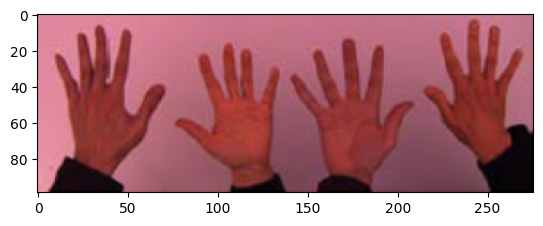

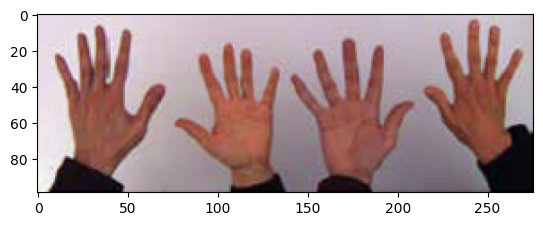

Imagen original: ./white_patch/test_green.png
Imagen procesada: ./white_patch_procesada/test_green_procesada.png
Cantidad de canales: 3
Tamaño de la imagen: (100, 278, 3) pix
Canal R Original : Mean=129.37	Std=40.23	Max=210
Canal R Procesado: Mean=156.62	Std=48.85	Max=255
Canal G Original : Mean=131.06	Std=57.11	Max=250
Canal G Procesado: Mean=133.18	Std=58.22	Max=255
Canal B Original : Mean=83.55	Std=40.90	Max=171
Canal B Procesado: Mean=124.11	Std=60.96	Max=255


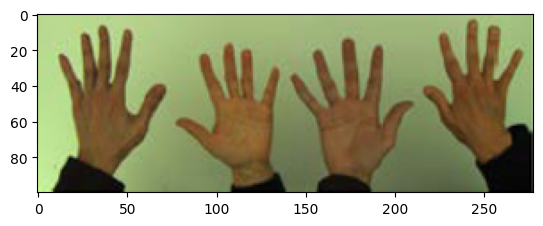

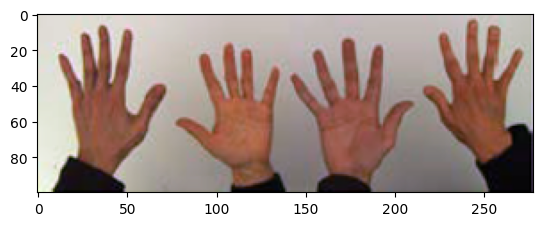

Imagen original: ./white_patch/test_blue.png
Imagen procesada: ./white_patch_procesada/test_blue_procesada.png
Cantidad de canales: 3
Tamaño de la imagen: (100, 278, 3) pix
Canal R Original : Mean=103.02	Std=31.94	Max=165
Canal R Procesado: Mean=158.75	Std=49.36	Max=255
Canal G Original : Mean=69.48	Std=30.57	Max=138
Canal G Procesado: Mean=127.91	Std=56.48	Max=255
Canal B Original : Mean=100.70	Std=48.24	Max=200
Canal B Procesado: Mean=127.91	Std=61.49	Max=255


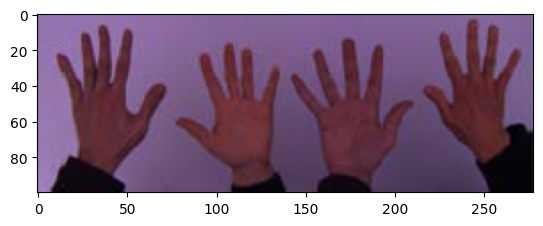

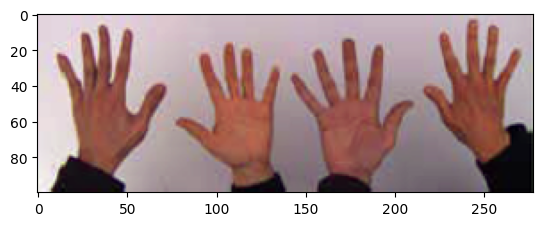

Imagen original: ./white_patch/wp_red.png
Imagen procesada: ./white_patch_procesada/wp_red_procesada.png
Cantidad de canales: 3
Tamaño de la imagen: (813, 481, 3) pix
Canal R Original : Mean=122.85	Std=81.78	Max=255
Canal R Procesado: Mean=122.85	Std=81.78	Max=255
Canal G Original : Mean=18.82	Std=18.68	Max=134
Canal G Procesado: Mean=35.31	Std=35.54	Max=255
Canal B Original : Mean=25.24	Std=25.67	Max=122
Canal B Procesado: Mean=52.31	Std=53.63	Max=255


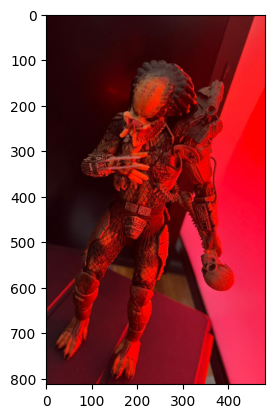

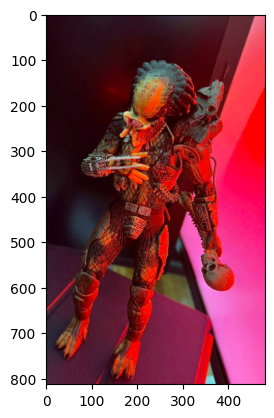

Imagen original: ./white_patch/wp_green.png
Imagen procesada: ./white_patch_procesada/wp_green_procesada.png
Cantidad de canales: 3
Tamaño de la imagen: (571, 363, 3) pix
Canal R Original : Mean=26.20	Std=23.19	Max=126
Canal R Procesado: Mean=52.66	Std=46.84	Max=255
Canal G Original : Mean=102.85	Std=70.50	Max=252
Canal G Procesado: Mean=103.51	Std=71.26	Max=255
Canal B Original : Mean=34.75	Std=29.86	Max=155
Canal B Procesado: Mean=56.69	Std=49.12	Max=255


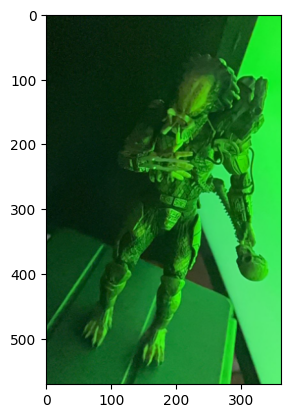

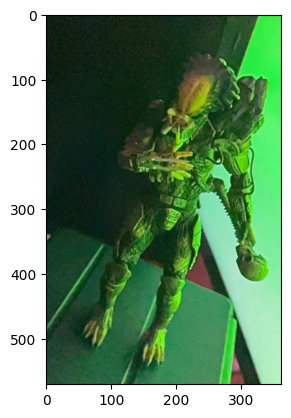

Imagen original: ./white_patch/wp_blue.jpg
Imagen procesada: ./white_patch_procesada/wp_blue_procesada.jpg
Cantidad de canales: 3
Tamaño de la imagen: (1600, 1200, 3) pix
Canal R Original : Mean=17.57	Std=22.08	Max=255
Canal R Procesado: Mean=17.57	Std=22.08	Max=255
Canal G Original : Mean=17.13	Std=19.20	Max=255
Canal G Procesado: Mean=17.13	Std=19.20	Max=255
Canal B Original : Mean=121.49	Std=72.45	Max=255
Canal B Procesado: Mean=121.49	Std=72.45	Max=255


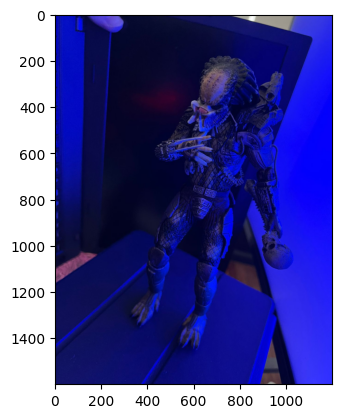

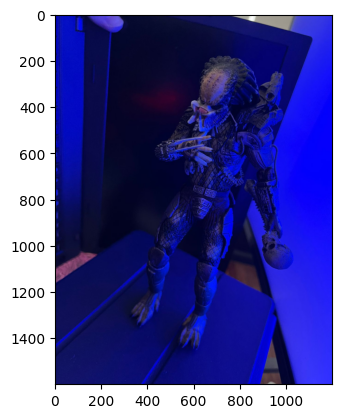

Imagen original: ./white_patch/wp_red2.jpg
Imagen procesada: ./white_patch_procesada/wp_red2_procesada.jpg
Cantidad de canales: 3
Tamaño de la imagen: (1600, 1200, 3) pix
Canal R Original : Mean=128.51	Std=83.91	Max=255
Canal R Procesado: Mean=128.51	Std=83.91	Max=255
Canal G Original : Mean=20.97	Std=23.91	Max=201
Canal G Procesado: Mean=26.16	Std=30.28	Max=255
Canal B Original : Mean=29.67	Std=29.77	Max=203
Canal B Procesado: Mean=36.83	Std=37.34	Max=255


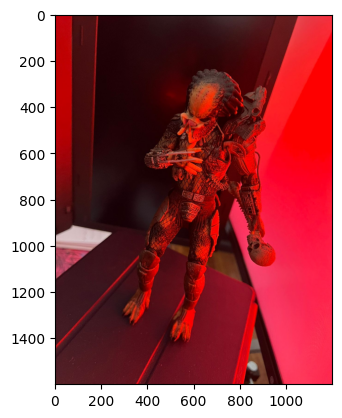

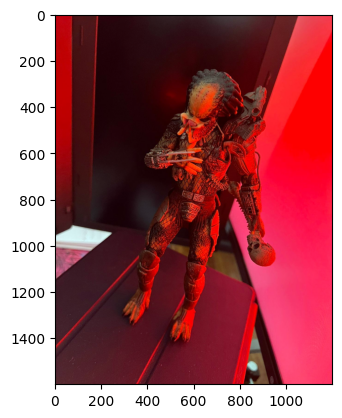

Imagen original: ./white_patch/wp_green2.jpg
Imagen procesada: ./white_patch_procesada/wp_green2_procesada.jpg
Cantidad de canales: 3
Tamaño de la imagen: (1600, 1200, 3) pix
Canal R Original : Mean=4.36	Std=13.60	Max=170
Canal R Procesado: Mean=6.42	Std=20.36	Max=255
Canal G Original : Mean=126.11	Std=85.10	Max=255
Canal G Procesado: Mean=126.11	Std=85.10	Max=255
Canal B Original : Mean=4.00	Std=10.19	Max=172
Canal B Procesado: Mean=5.60	Std=15.02	Max=255


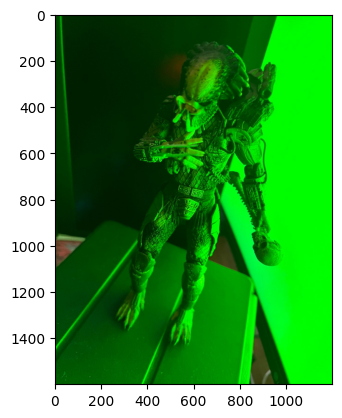

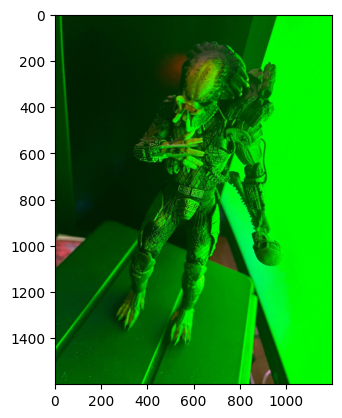

In [4]:
# Aplicación del algoritmo de White Patch a las imágenes de la carpeta
white_patch('./white_patch/test_red.png', './white_patch_procesada/test_red_procesada.png', showInfo=True)
white_patch('./white_patch/test_green.png', './white_patch_procesada/test_green_procesada.png', showInfo=True)
white_patch('./white_patch/test_blue.png', './white_patch_procesada/test_blue_procesada.png', showInfo=True)
white_patch('./white_patch/wp_red.png', './white_patch_procesada/wp_red_procesada.png', showInfo=True)
white_patch('./white_patch/wp_green.png', './white_patch_procesada/wp_green_procesada.png', showInfo=True)
white_patch('./white_patch/wp_blue.jpg', './white_patch_procesada/wp_blue_procesada.jpg', showInfo=True)
white_patch('./white_patch/wp_red2.jpg', './white_patch_procesada/wp_red2_procesada.jpg', showInfo=True)
white_patch('./white_patch/wp_green2.jpg', './white_patch_procesada/wp_green2_procesada.jpg', showInfo=True)

<h1><strong>Análisis de los resultados<strong></h1>

<p>Cuanto mas grande es el valor máximo global de los pixeles de un canal (RGB) menor es la normalización en dicho canal aplicado por el algoritmo White-Patch. Esto se nota especialmente en las imagenes <em>./white_patch/wp_blue.jpg</em> y <em>./white_patch/wp_red2.jpg</em></p>

<p>La normalización del algoritmo White-Patch se nota bastante en la imagen <em>./white_patch/wp_red.png</em>. El canal rojo R tiene un máximo global bastante mas grande los de los otros dos canales verde G y azul B. Es por este motivo que en este caso el algoritmo White-Patch aumenta mucho la intensidad de los canales verde y azul</p>

<h1><strong>Parte 2</strong></h1>

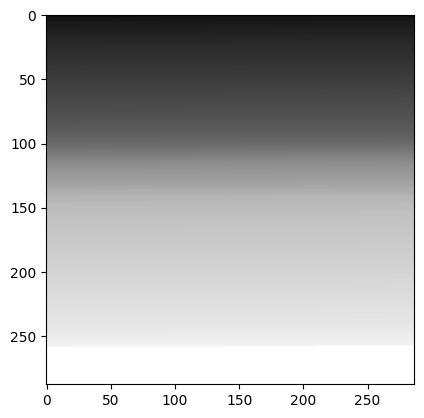

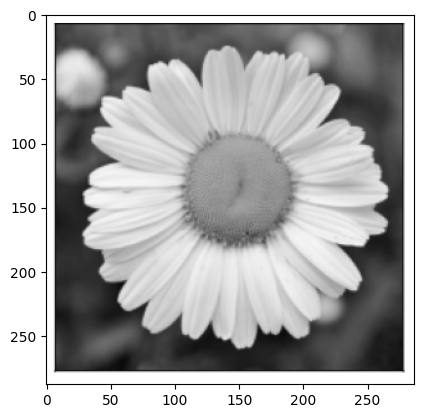

In [5]:
img1 = cv.imread('./img1_tp.png', cv.IMREAD_GRAYSCALE)
img2 = cv.imread('./img2_tp.png', cv.IMREAD_GRAYSCALE)

plt.figure()
plt.imshow(img1, cmap='gray')
plt.show()
plt.figure()
plt.imshow(img2, cmap='gray')
plt.show()